In [32]:
# DSCI-552-HW6
# 1.(a)

import pandas as pd
import numpy as np

train = pd.read_csv(
    '../Data/aps_failure_training_set.csv',
    skiprows=20,
    na_values='na'
)

test = pd.read_csv(
    '../Data/aps_failure_test_set.csv',
    skiprows=20,
    na_values='na'
)

print("Training set:", train.shape)
print("Test set:", test.shape)

Training set: (60000, 171)
Test set: (16000, 171)


In [33]:
# (b)(i)
from sklearn.impute import SimpleImputer

X_train = train.drop(columns=['class'])
X_test = test.drop(columns=['class'])

y_train = train['class']
y_test = test['class']

imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

print("Training missing values:", X_train.isnull().sum().sum())
print("Test missing values:", X_test.isnull().sum().sum())

Training missing values: 0
Test missing values: 0


In this homework, I used median imputation to fill missing values because it is less sensitive to outliers and avoids removing a large amount of data.

In [34]:
# (b)(ii)
cv = X_train.std() / X_train.mean()

cv_df = pd.DataFrame({
    'Feature': cv.index,
    'CV': cv.values
})

cv_df

,Feature,CV
0,aa_000,2.450938
1,ab_000,10.383494
2,ac_000,2.310241
3,ad_000,244.322816
4,ae_000,24.200137
...,...,...
165,ee_007,5.012754
166,ee_008,3.259079
167,ee_009,5.691612
168,ef_000,49.366659


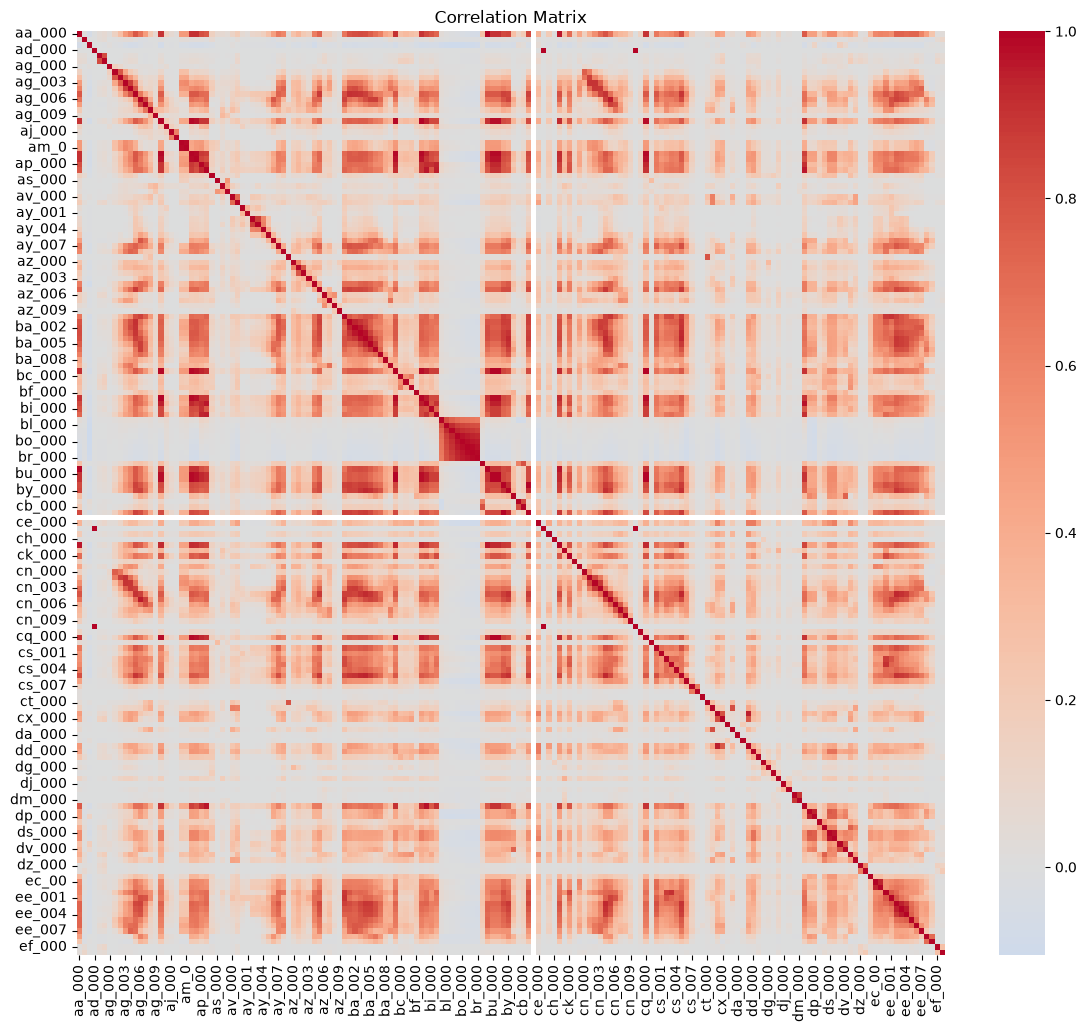

In [35]:
# (b)(iii)
import matplotlib.pyplot as plt
import seaborn as sns

corr = X_train.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

In [36]:
# (b)(iv)

top_features = cv.sort_values(ascending=False).head(13).index

print(top_features.tolist())

['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


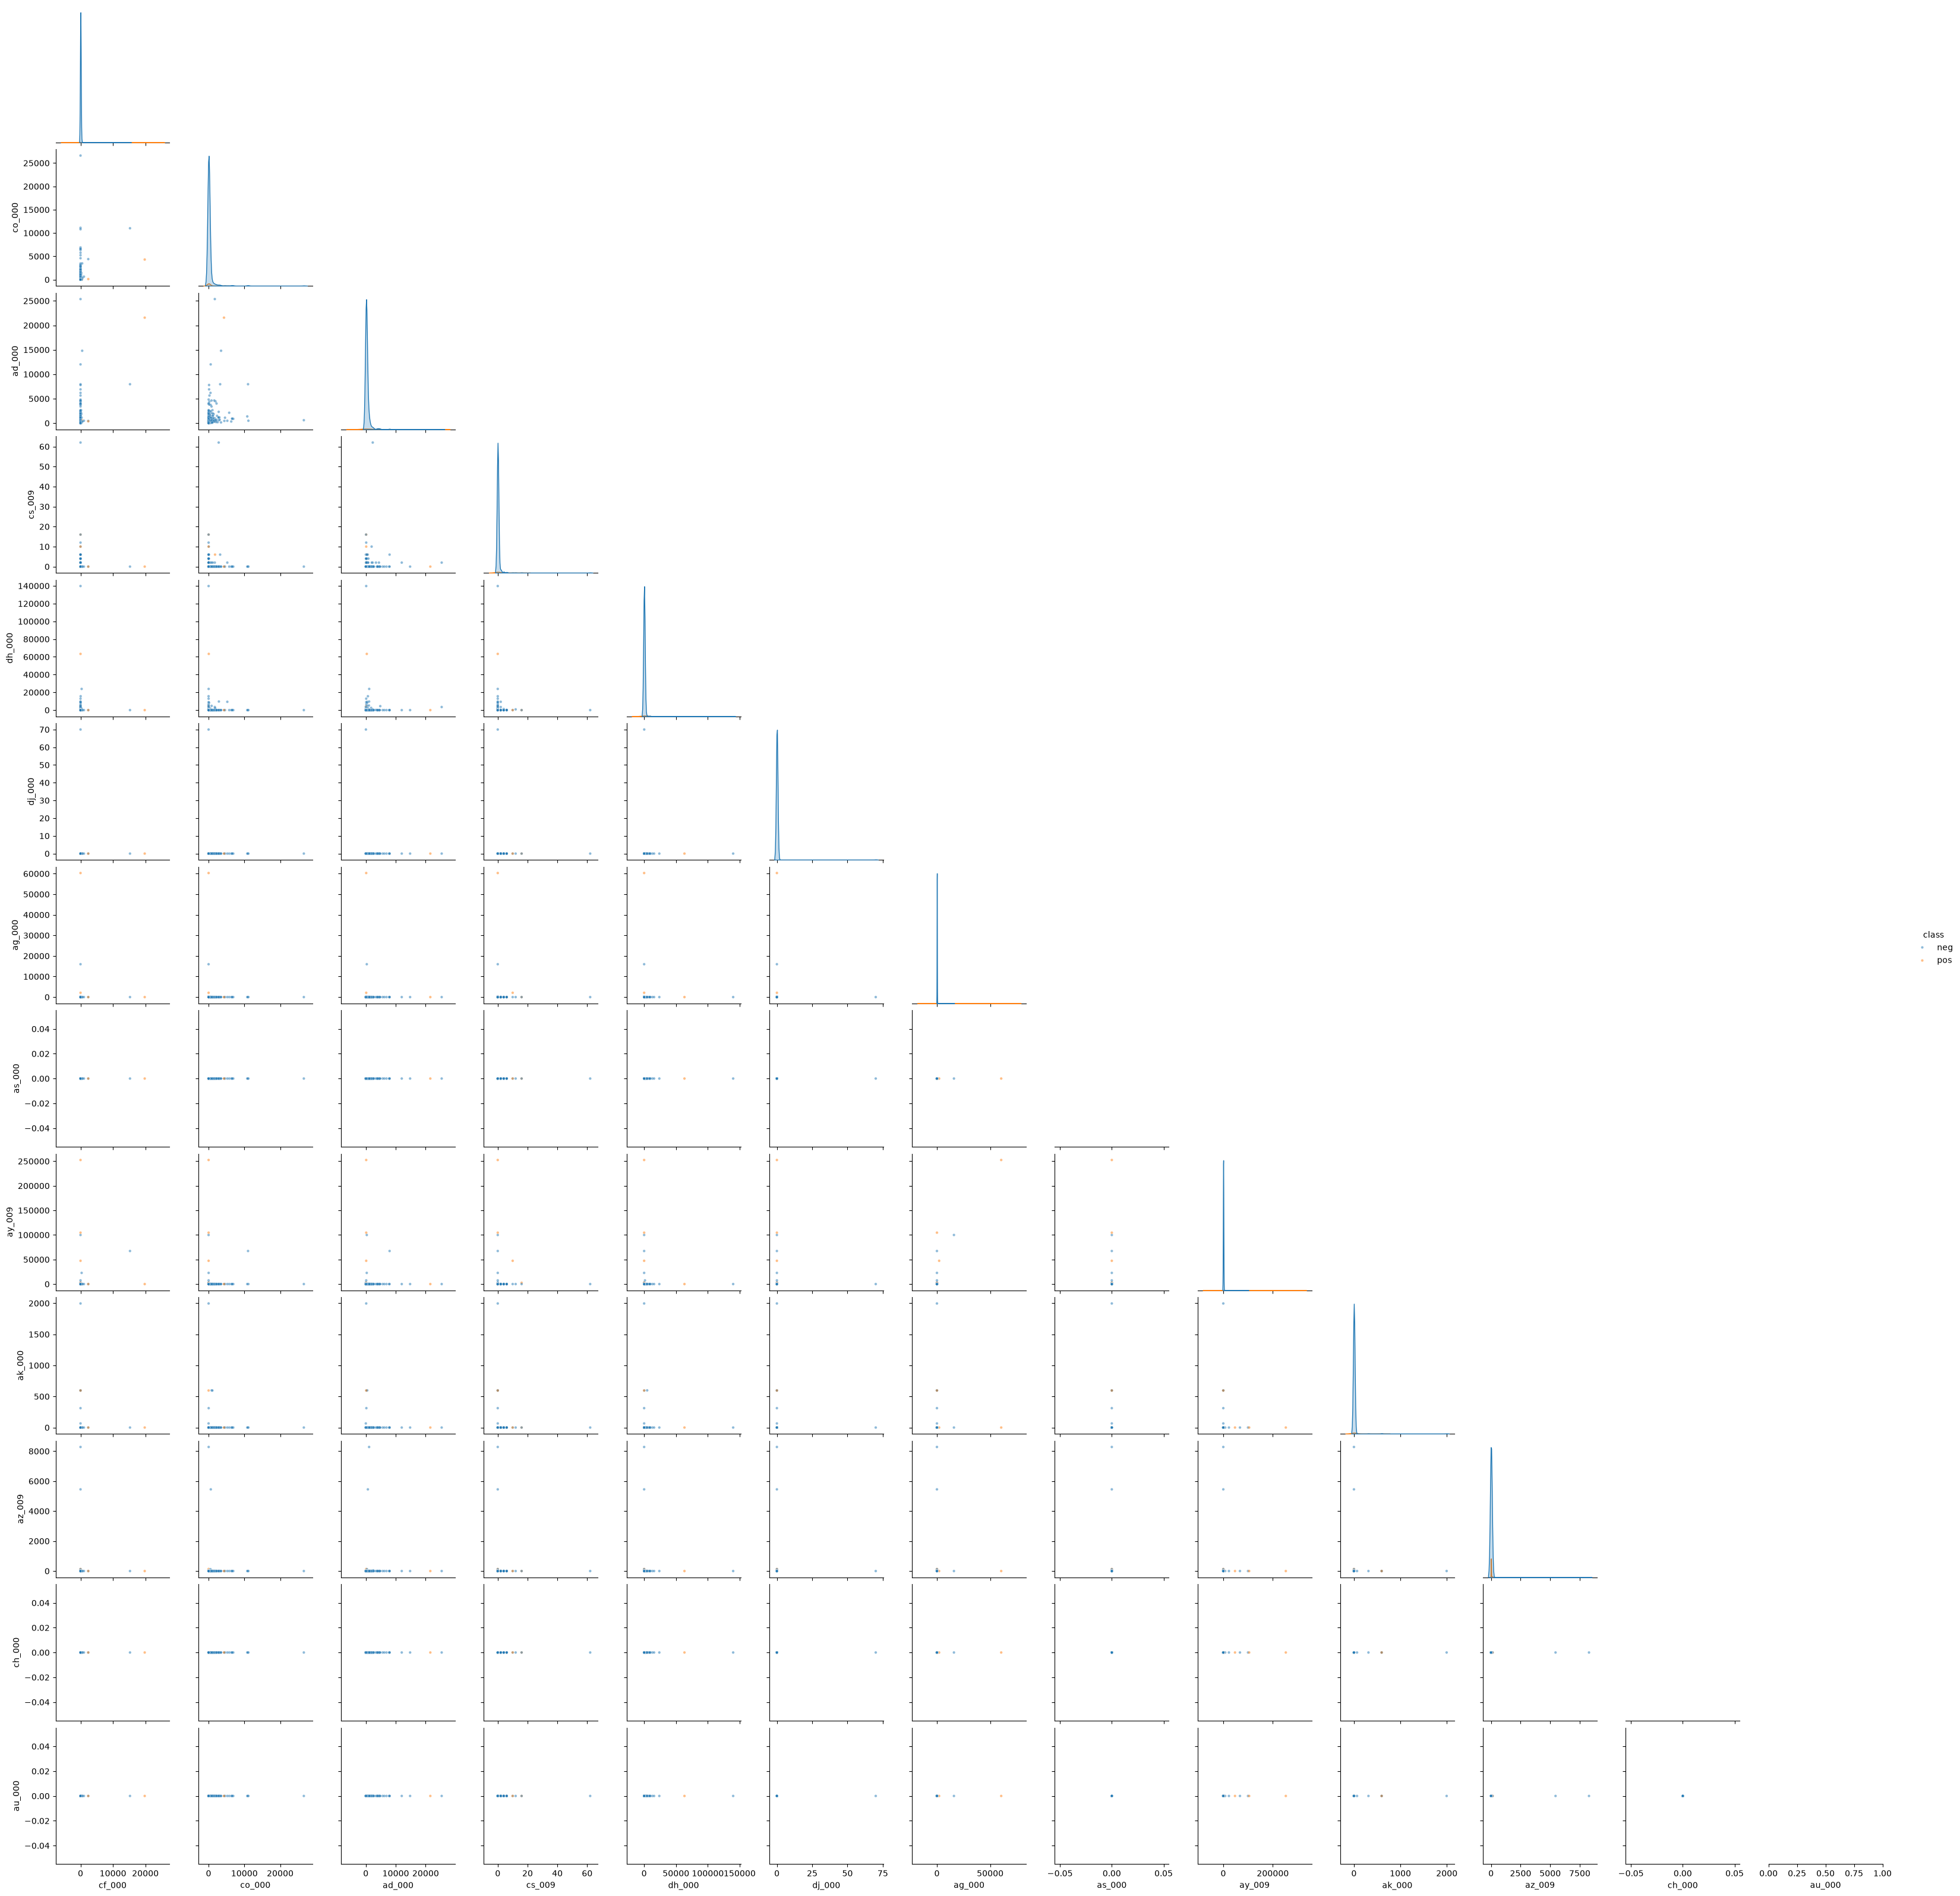

In [37]:
# Draw Scatter Plots
plot_data = X_train[top_features].copy()
plot_data['class'] = y_train.values

sns.pairplot(
    plot_data.sample(n=1000, random_state=42),
    hue='class',
    corner=True,
    plot_kws={'alpha': 0.5, 's': 10}
)

plt.show()

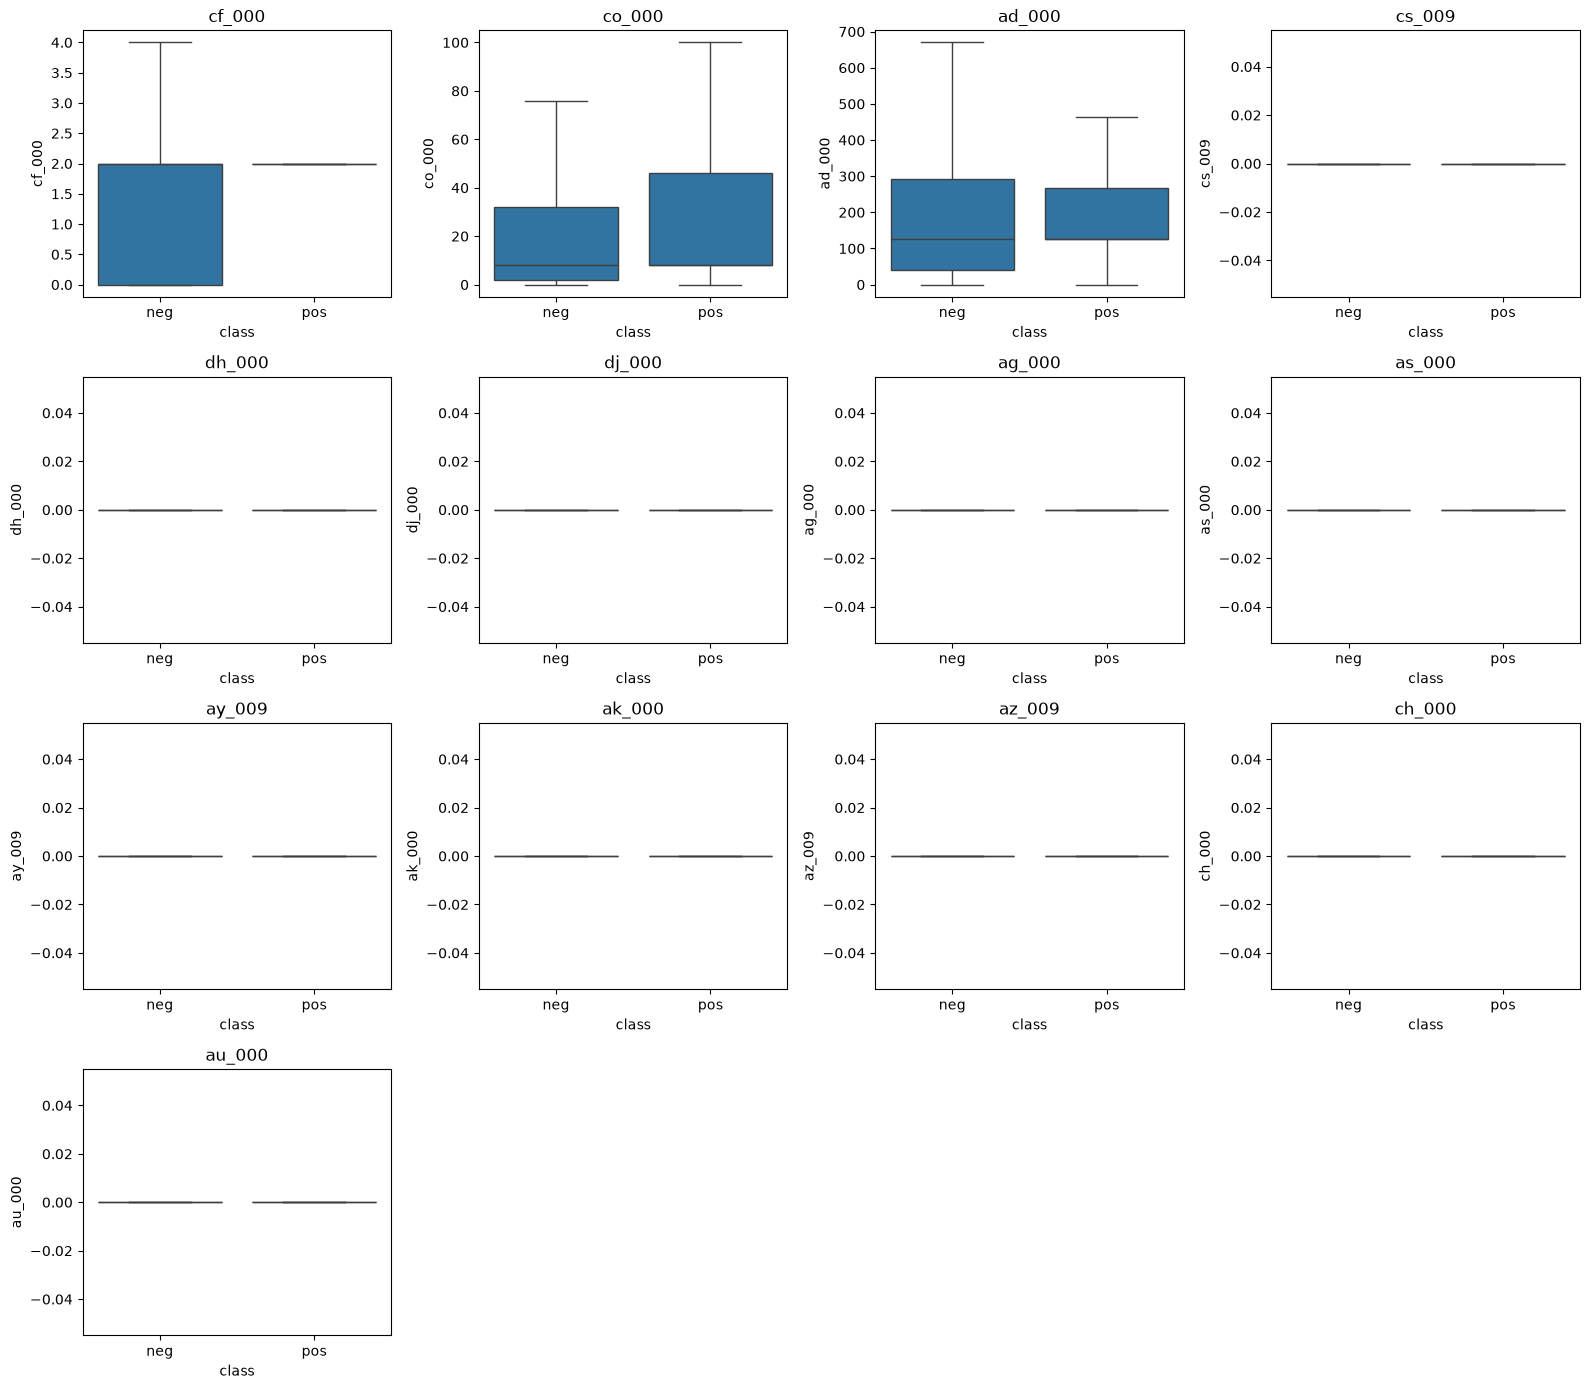

In [38]:
# Draw Box Plots
fig, axes = plt.subplots(4, 4, figsize=(16, 14))

for i, feature in enumerate(top_features):
    sns.boxplot(
        data=plot_data,
        x='class',
        y=feature,
        ax=axes.flat[i],
        showfliers=False
    )
    axes.flat[i].set_title(feature)

for ax in axes.flat[13:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

No, we cannot draw conclusions about the significance of the features merely based on the scatter plot.

In [39]:
# (b)(v)
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

class
neg    59000
pos     1000
Name: count, dtype: int64
class
neg    98.333333
pos     1.666667
Name: proportion, dtype: float64


The training set contains 59,000 negative samples (98.33%) and 1,000 positive samples (1.67%). The dataset is highly imbalanced because the negative class significantly outnumbers the positive class.

In [40]:
# (c)
# Training Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.

Training Confusion Matrix:
[[59000     0]
 [    1   999]]

Test Confusion Matrix:
[[15610    15]
 [  106   269]]

Training Error: 1.666666666666483e-05
Test Error: 0.0075625000000000275


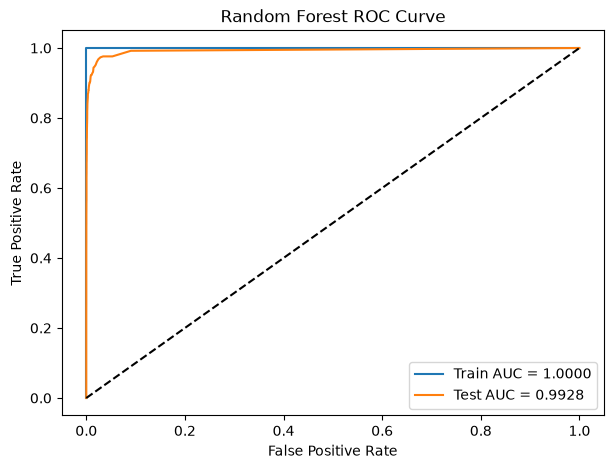


OOB Error: 0.006116666666666659
Test Error: 0.0075625000000000275


In [41]:
# Predictions
y_train_pred = rf.predict(X_train)
y_test_pred = rf.predict(X_test)

# Confusion Matrix
print("Training Confusion Matrix:")
print(confusion_matrix(y_train, y_train_pred, labels=['neg', 'pos']))

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=['neg', 'pos']))

# Misclassification Rate
train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)

print("\nTraining Error:", train_error)
print("Test Error:", test_error)

# ROC and AUC
y_train_prob = rf.predict_proba(X_train)[:, list(rf.classes_).index('pos')]
y_test_prob = rf.predict_proba(X_test)[:, list(rf.classes_).index('pos')]

train_auc = roc_auc_score(y_train, y_train_prob)
test_auc = roc_auc_score(y_test, y_test_prob)

fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob, pos_label='pos')
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob, pos_label='pos')

plt.figure(figsize=(7, 5))
plt.plot(fpr_train, tpr_train, label=f'Train AUC = {train_auc:.4f}')
plt.plot(fpr_test, tpr_test, label=f'Test AUC = {test_auc:.4f}')
plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest ROC Curve')
plt.legend()
plt.show()

# Out-of-Bag Error
oob_error = 1 - rf.oob_score_

print("\nOOB Error:", oob_error)
print("Test Error:", test_error)

The Random Forest achieved a training error of 0.000017 and a test error of 0.007563, with AUC values of 1.0000 and 0.9928, respectively.

The OOB error (0.006112) is close to the test error (0.007563), suggesting that the OOB estimate is reasonably accurate.

Although the model performs well overall, it misclassifies 106 positive samples in the test set, which may be related to class imbalance.

In [42]:
# (d) Random Forest with balanced subsample weights
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced_subsample',
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train, y_train)

# Check OOB predictions
oob_probs = rf_balanced.oob_decision_function_
print("Samples without OOB predictions:",
      (oob_probs.sum(axis=1) == 0).sum())

print("OOB Error:", 1 - rf_balanced.oob_score_)


Samples without OOB predictions: 0
OOB Error: 0.008033333333333337


Training Confusion Matrix:
[[59000     0]
 [    1   999]]

Test Confusion Matrix:
[[15608    17]
 [  158   217]]

Training Error: 1.666666666666483e-05
Test Error: 0.010937500000000044


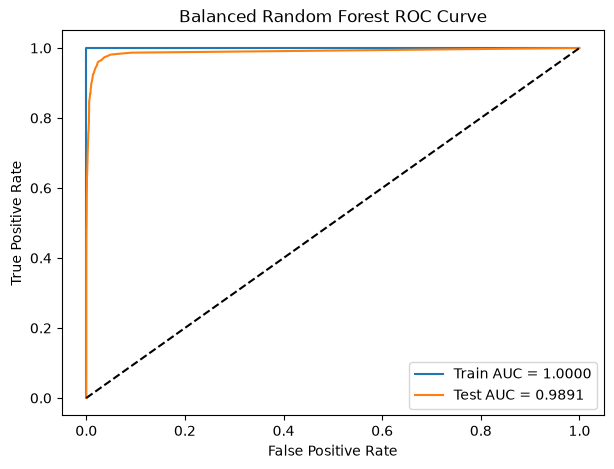


Model Comparison:


,Metric,Random Forest,Balanced Random Forest
0,Train Error,0.000017,0.000017
1,Test Error,0.007563,0.010938
2,Train AUC,1.000000,1.000000
3,Test AUC,0.992754,0.989149
4,OOB Error,0.006117,0.008033


In [43]:
# Predictions
y_train_pred_bal = rf_balanced.predict(X_train)
y_test_pred_bal = rf_balanced.predict(X_test)

# Confusion Matrix
print("Training Confusion Matrix:")
print(confusion_matrix(y_train, y_train_pred_bal, labels=['neg', 'pos']))

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_bal, labels=['neg', 'pos']))

# Misclassification Rate
train_error_bal = 1 - accuracy_score(y_train, y_train_pred_bal)
test_error_bal = 1 - accuracy_score(y_test, y_test_pred_bal)

print("\nTraining Error:", train_error_bal)
print("Test Error:", test_error_bal)

# ROC and AUC
y_train_prob_bal = rf_balanced.predict_proba(X_train)[:, 1]
y_test_prob_bal = rf_balanced.predict_proba(X_test)[:, 1]

train_auc_bal = roc_auc_score(y_train, y_train_prob_bal)
test_auc_bal = roc_auc_score(y_test, y_test_prob_bal)

fpr_train_bal, tpr_train_bal, _ = roc_curve(
    y_train, y_train_prob_bal, pos_label='pos'
)
fpr_test_bal, tpr_test_bal, _ = roc_curve(
    y_test, y_test_prob_bal, pos_label='pos'
)

plt.figure(figsize=(7, 5))
plt.plot(fpr_train_bal, tpr_train_bal, label=f'Train AUC = {train_auc_bal:.4f}')
plt.plot(fpr_test_bal, tpr_test_bal, label=f'Test AUC = {test_auc_bal:.4f}')
plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Balanced Random Forest ROC Curve')
plt.legend()
plt.show()

# OOB Error
oob_error_bal = 1 - rf_balanced.oob_score_

# Compare with (c)
comparison = pd.DataFrame({
    'Metric': ['Train Error', 'Test Error', 'Train AUC', 'Test AUC', 'OOB Error'],
    'Random Forest': [
        train_error, test_error, train_auc, test_auc, oob_error
    ],
    'Balanced Random Forest': [
        train_error_bal, test_error_bal,
        train_auc_bal, test_auc_bal, oob_error_bal
    ]
})

print("\nModel Comparison:")
display(comparison)

Class imbalance in Random Forests can be addressed using class weighting, oversampling, or undersampling. In this case, I used class_weight='balanced_subsample' to assign higher weights to the minority class.

Compared with the original Random Forest, the balanced model had a higher test error (0.010938 vs. 0.007563) and a slightly lower test AUC (0.9891 vs. 0.9928). The number of false negatives also increased from 106 to 158.

Therefore, class imbalance compensation did not improve the model's performance in this case.

In [44]:
# (e) 
# XGBoost with L1 Regularization
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Convert class labels to 0 and 1
y_train_xgb = y_train.map({'neg': 0, 'pos': 1})
y_test_xgb = y_test.map({'neg': 0, 'pos': 1})

# XGBoost model without class imbalance compensation
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# Select the best L1 regularization parameter
param_grid = {
    'reg_alpha': [0.01, 0.1, 1, 10]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    xgb,
    param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=1
)

grid.fit(X_train, y_train_xgb)

xgb_best = grid.best_estimator_

print("Best alpha:", grid.best_params_['reg_alpha'])
print("CV Error:", 1 - grid.best_score_)

Best alpha: 1
CV Error: 0.007033333333333225


Training Confusion Matrix:
[[58940    60]
 [  227   773]]

Test Confusion Matrix:
[[15604    21]
 [  116   259]]

Training Error: 0.004783333333333362
CV Error: 0.007033333333333225
Test Error: 0.008562500000000028


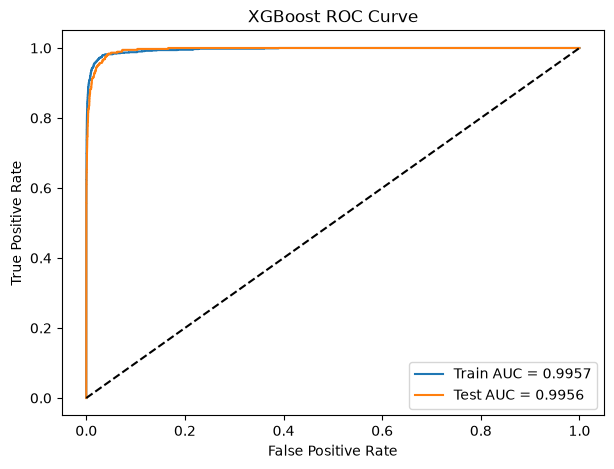

In [45]:
# Predictions
y_train_pred_xgb = xgb_best.predict(X_train)
y_test_pred_xgb = xgb_best.predict(X_test)

# Confusion Matrix
print("Training Confusion Matrix:")
print(confusion_matrix(y_train_xgb, y_train_pred_xgb))

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test_xgb, y_test_pred_xgb))

# Misclassification Rate
train_error_xgb = 1 - accuracy_score(y_train_xgb, y_train_pred_xgb)
test_error_xgb = 1 - accuracy_score(y_test_xgb, y_test_pred_xgb)

print("\nTraining Error:", train_error_xgb)
print("CV Error:", 1 - grid.best_score_)
print("Test Error:", test_error_xgb)

# ROC and AUC
y_train_prob_xgb = xgb_best.predict_proba(X_train)[:, 1]
y_test_prob_xgb = xgb_best.predict_proba(X_test)[:, 1]

train_auc_xgb = roc_auc_score(y_train_xgb, y_train_prob_xgb)
test_auc_xgb = roc_auc_score(y_test_xgb, y_test_prob_xgb)

fpr_train_xgb, tpr_train_xgb, _ = roc_curve(
    y_train_xgb, y_train_prob_xgb
)
fpr_test_xgb, tpr_test_xgb, _ = roc_curve(
    y_test_xgb, y_test_prob_xgb
)

plt.figure(figsize=(7, 5))
plt.plot(fpr_train_xgb, tpr_train_xgb,
         label=f'Train AUC = {train_auc_xgb:.4f}')
plt.plot(fpr_test_xgb, tpr_test_xgb,
         label=f'Test AUC = {test_auc_xgb:.4f}')
plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost ROC Curve')
plt.legend()
plt.show()

The best alpha was 1 using 5-fold cross-validation. The CV error (0.00703) was close to the test error (0.00856). Both training and test AUC were high (0.9957 and 0.9956), indicating good model performance.

In [46]:
# (f) 
# MOTE + XGBoost
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier

# Pipeline with SMOTE and XGBoost
pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('xgb', XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

# Select the best alpha
param_grid_smote = {
    'xgb__reg_alpha': [0.01, 0.1, 1, 10]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_smote = GridSearchCV(
    pipeline,
    param_grid_smote,
    cv=cv,
    scoring='accuracy',
    n_jobs=1
)

grid_smote.fit(X_train, y_train_xgb)

smote_best = grid_smote.best_estimator_

print("Best alpha:", grid_smote.best_params_['xgb__reg_alpha'])
print("CV Error:", 1 - grid_smote.best_score_)

Best alpha: 0.01
CV Error: 0.02063333333333328


Training Confusion Matrix:
[[57923  1077]
 [   72   928]]

Test Confusion Matrix:
[[15359   266]
 [   28   347]]

Training Error: 0.01915
CV Error: 0.02063333333333328
Test Error: 0.01837500000000003


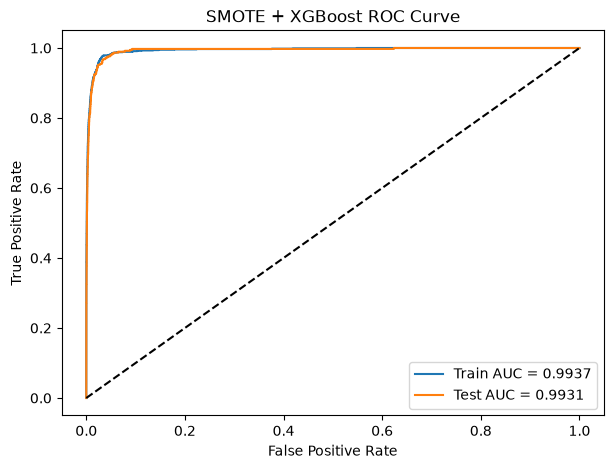


Model Comparison:


,Metric,XGBoost,SMOTE + XGBoost
0,Train Error,0.004783,0.019150
1,CV Error,0.007033,0.020633
2,Test Error,0.008563,0.018375
3,Train AUC,0.995657,0.993707
4,Test AUC,0.995562,0.993073


In [47]:
# Predictions
y_train_pred_smote = smote_best.predict(X_train)
y_test_pred_smote = smote_best.predict(X_test)

# Confusion Matrix
print("Training Confusion Matrix:")
print(confusion_matrix(y_train_xgb, y_train_pred_smote))

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test_xgb, y_test_pred_smote))

# Misclassification Rate
train_error_smote = 1 - accuracy_score(y_train_xgb, y_train_pred_smote)
test_error_smote = 1 - accuracy_score(y_test_xgb, y_test_pred_smote)

print("\nTraining Error:", train_error_smote)
print("CV Error:", 1 - grid_smote.best_score_)
print("Test Error:", test_error_smote)

# ROC and AUC
y_train_prob_smote = smote_best.predict_proba(X_train)[:, 1]
y_test_prob_smote = smote_best.predict_proba(X_test)[:, 1]

train_auc_smote = roc_auc_score(y_train_xgb, y_train_prob_smote)
test_auc_smote = roc_auc_score(y_test_xgb, y_test_prob_smote)

fpr_train_smote, tpr_train_smote, _ = roc_curve(
    y_train_xgb, y_train_prob_smote
)
fpr_test_smote, tpr_test_smote, _ = roc_curve(
    y_test_xgb, y_test_prob_smote
)

plt.figure(figsize=(7, 5))
plt.plot(fpr_train_smote, tpr_train_smote,
         label=f'Train AUC = {train_auc_smote:.4f}')
plt.plot(fpr_test_smote, tpr_test_smote,
         label=f'Test AUC = {test_auc_smote:.4f}')
plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('SMOTE + XGBoost ROC Curve')
plt.legend()
plt.show()

# Compare with (e)
comparison_smote = pd.DataFrame({
    'Metric': ['Train Error', 'CV Error', 'Test Error',
               'Train AUC', 'Test AUC'],
    'XGBoost': [
        train_error_xgb, 1 - grid.best_score_,
        test_error_xgb, train_auc_xgb, test_auc_xgb
    ],
    'SMOTE + XGBoost': [
        train_error_smote, 1 - grid_smote.best_score_,
        test_error_smote, train_auc_smote, test_auc_smote
    ]
})

print("\nModel Comparison:")
display(comparison_smote)

The best alpha was 0.01.

Compared with XGBoost without SMOTE, the test error increased from 0.00856 to 0.01838, and the test AUC decreased from 0.9956 to 0.9931. However, false negatives decreased from 116 to 28, while false positives increased from 21 to 266.

Overall, SMOTE improved minority class detection but increased the overall error.

### 2.ISLR 6.6.3
**(a) iv. Steadily decrease.**

As s increases, the constraint becomes less restrictive, allowing the model to fit the training data better. Therefore, training RSS decreases.

**(b) ii. Decrease initially, then increase.**

As s increases, the model becomes more flexible. Test RSS initially decreases due to lower bias, but eventually increases due to overfitting.

**(c) iii. Steadily increase.**

As s increases, the model becomes more flexible and more sensitive to the training data, leading to higher variance.

**(d) iv. Steadily decrease.**

As s increases, the model becomes less restrictive and can better capture the true relationship, reducing squared bias.

**(e) v. Remain constant.**

Irreducible error is independent of model flexibility, so it remains constant as s increases.

### 3. ISLR, 6.6.5
**(a)** The ridge regression optimization problem is:
$$
\min_{\beta_1,\beta_2}
2(y_1-a(\beta_1+\beta_2))^2+\lambda(\beta_1^2+\beta_2^2)
$$

where $x_{11}=x_{12}=a$, $x_{21}=x_{22}=-a$, and $y_2=-y_1$.

**(b)** Taking the partial derivatives with respect to $\beta_1$ and $\beta_2$:

$$
-4a(y_1-a(\beta_1+\beta_2))+2\lambda\beta_1=0
$$

$$
-4a(y_1-a(\beta_1+\beta_2))+2\lambda\beta_2=0
$$

Subtracting the two equations gives:

$$
2\lambda(\beta_1-\beta_2)=0
$$

Since $\lambda>0$, we obtain $\hat{\beta}_1=\hat{\beta}_2$.

Therefore, ridge regression assigns equal coefficients to the two identical predictors.

**(c)** The lasso optimization problem is:

$$
\min_{\beta_1,\beta_2}
2(y_1-a(\beta_1+\beta_2))^2+\lambda(|\beta_1|+|\beta_2|)
$$

**(d)** The RSS depends only on the sum $\beta_1+\beta_2$.

By the triangle inequality:

$$
|\beta_1|+|\beta_2|\geq|\beta_1+\beta_2|
$$

Equality holds when $\beta_1$ and $\beta_2$ have the same sign or one is zero.

Let $t^*$ be the optimal value of $\beta_1+\beta_2$. Any pair satisfying

$$
\beta_1+\beta_2=t^*
$$

with both coefficients having the same sign (or one being zero) achieves the same minimum.

Therefore, when $t^*\neq 0$, the lasso solution is not unique. Possible solutions include $(t^*,0)$, $(0,t^*)$, and all pairs between them.

If $t^*=0$, the unique solution is $(0,0)$.

### 4. ISLR 8.4.5
**Majority Vote:**

Each tree predicts Red if the probability is greater than 0.5, and Green otherwise.

- Red: 6 votes (0.55, 0.6, 0.6, 0.65, 0.7, 0.75)
- Green: 4 votes (0.1, 0.15, 0.2, 0.2)

Since Red receives more votes, the final classification is Red.

**Average Probability:**

$$
\bar{p} = \frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}=0.45
$$

Since $0.45 < 0.5$, the final classification is Green.

**Conclusion:**

The two methods give different results. Majority voting predicts Red because more trees vote for Red, while averaging probabilities predicts Green because the trees voting for Green have stronger confidence.

### 5. ISLR 9.7.3

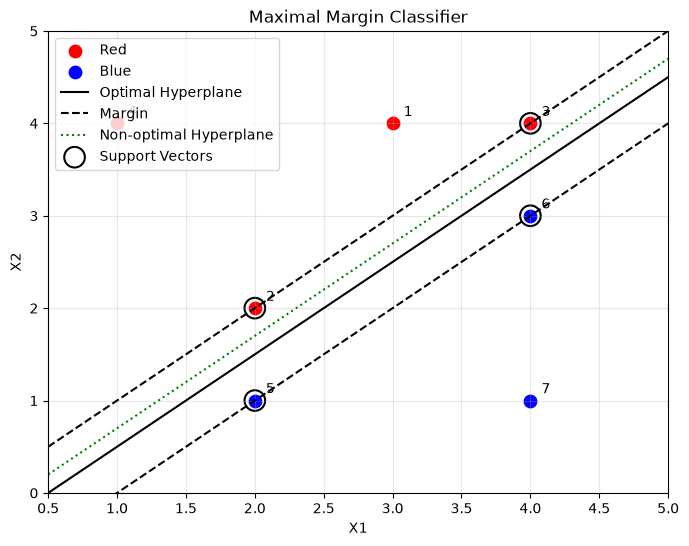

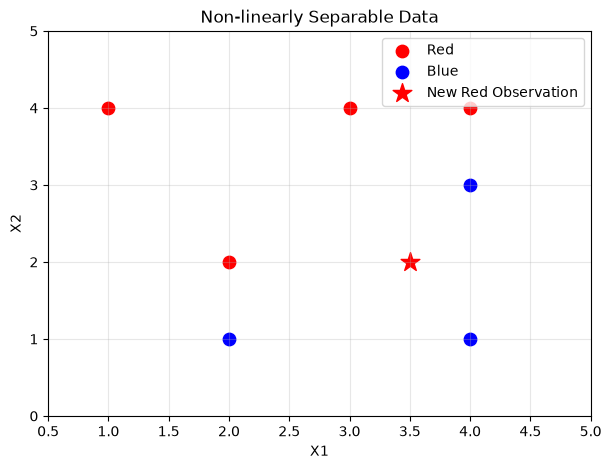

In [48]:
import numpy as np
import matplotlib.pyplot as plt

# Data
red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue = np.array([[2, 1], [4, 3], [4, 1]])

x = np.linspace(0.5, 5, 200)

# (a)-(g): Observations and separating hyperplanes
plt.figure(figsize=(8, 6))

plt.scatter(red[:, 0], red[:, 1], color='red', label='Red', s=80)
plt.scatter(blue[:, 0], blue[:, 1], color='blue', label='Blue', s=80)

for i, (x1, x2) in enumerate(np.vstack((red, blue))):
    plt.annotate(str(i + 1), (x1 + 0.08, x2 + 0.08))

# Optimal hyperplane
plt.plot(x, x - 0.5, 'k-', label='Optimal Hyperplane')

# Margin boundaries
plt.plot(x, x, 'k--', label='Margin')
plt.plot(x, x - 1, 'k--')

# Non-optimal separating hyperplane
plt.plot(x, x - 0.3, 'g:', label='Non-optimal Hyperplane')

# Support vectors
sv = np.array([[2, 2], [4, 4], [2, 1], [4, 3]])
plt.scatter(sv[:, 0], sv[:, 1], s=220,
            facecolors='none', edgecolors='black',
            linewidths=1.5, label='Support Vectors')

plt.xlim(0.5, 5)
plt.ylim(0, 5)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Maximal Margin Classifier')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# (h): Non-linearly separable data
plt.figure(figsize=(7, 5))

plt.scatter(red[:, 0], red[:, 1], color='red', label='Red', s=80)
plt.scatter(blue[:, 0], blue[:, 1], color='blue', label='Blue', s=80)

plt.scatter(3.5, 2, color='red', marker='*',
            s=200, label='New Red Observation')

plt.xlim(0.5, 5)
plt.ylim(0, 5)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Non-linearly Separable Data')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**(a) Sketch the observations**

The observations are plotted above, with four Red points and three Blue points.

**(b) Optimal Separating Hyperplane**

The optimal hyperplane lies halfway between the closest Red and Blue points. Its equation is:
$$
X_2 = X_1 - 0.5
$$
or equivalently,
$$
0.5 - X_1 + X_2 = 0
$$

**(c) Classification Rule**

Classify an observation as Red if:
$$
0.5 - X_1 + X_2 > 0
$$
Otherwise, classify it as Blue.
The coefficients are $\beta_0 = 0.5$, $\beta_1 = -1$, and $\beta_2 = 1$.

**(d) Margin**

The two margin boundaries are:
$$
X_2 = X_1 \quad \text{and} \quad X_2 = X_1 - 1
$$
The distance from the optimal hyperplane to either boundary is:
$$
M = \frac{0.5}{\sqrt{2}} \approx 0.354
$$

**(e) Support Vectors**

The support vectors are the four observations lying on the margin boundaries:
- Red: (2, 2) and (4, 4)
- Blue: (2, 1) and (4, 3)

**(f) Moving Observation 7**

Observation 7 (4, 1) is not a support vector. A slight movement would not affect the optimal hyperplane as long as it stays outside the margin.

**(g) Non-optimal Separating Hyperplane**

One possible non-optimal separating hyperplane is:
$$
X_2 = X_1 - 0.3
$$
This line separates the two classes but has a smaller margin, so it is not optimal.

**(h) Non-linearly Separable Data**

Add a Red observation at (3.5, 2), inside the region formed by the Blue points. Therefore, the two classes are no longer linearly separable.